<a href="https://colab.research.google.com/github/Saransh-Basu-01/50-Ml-Projects-to-understand-LLMs/blob/main/Project_24_Cosine_Similarity_within_and_across_Layers.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl

import requests

import torch
import torch.nn.functional as F

from transformers import AutoModelForCausalLM, AutoTokenizer

# Part 1: Extract hidden states

## Task_1:
- Import GPT-2-medium and switch it to eval mode. Inspect the
model.config to find the attribute that encodes the number of
transformers layers.
Tokenize the sentence A wise man once said: Penguins are
cute. (including the period.) Input the text directly into the
tokenizer variable instead of using the encode method. Inspect the
output of the tokenizer.
Run a forward pass with the tokens. Use the output_hidden_states
optional input argument to get the hidden states in the model output.
The model output is a dictionary. Print the keys in that dic
tionary, the size of the output logits, the number of hidden states,
and the size of each hidden state (all hidden states have the same
size)

In [2]:
# GPT2 model and its tokenizer
model = AutoModelForCausalLM.from_pretrained('gpt2-medium')
tokenizer = AutoTokenizer.from_pretrained('gpt2')

# toggle model into "evaluation" mode
model.eval()

config.json:   0%|          | 0.00/718 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.52GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/292 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/665 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.04M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

GPT2LMHeadModel(
  (transformer): GPT2Model(
    (wte): Embedding(50257, 1024)
    (wpe): Embedding(1024, 1024)
    (drop): Dropout(p=0.1, inplace=False)
    (h): ModuleList(
      (0-23): 24 x GPT2Block(
        (ln_1): LayerNorm((1024,), eps=1e-05, elementwise_affine=True)
        (attn): GPT2Attention(
          (c_attn): Conv1D(nf=3072, nx=1024)
          (c_proj): Conv1D(nf=1024, nx=1024)
          (attn_dropout): Dropout(p=0.1, inplace=False)
          (resid_dropout): Dropout(p=0.1, inplace=False)
        )
        (ln_2): LayerNorm((1024,), eps=1e-05, elementwise_affine=True)
        (mlp): GPT2MLP(
          (c_fc): Conv1D(nf=4096, nx=1024)
          (c_proj): Conv1D(nf=1024, nx=4096)
          (act): NewGELUActivation()
          (dropout): Dropout(p=0.1, inplace=False)
        )
      )
    )
    (ln_f): LayerNorm((1024,), eps=1e-05, elementwise_affine=True)
  )
  (lm_head): Linear(in_features=1024, out_features=50257, bias=False)
)

In [3]:
tokenizer

GPT2Tokenizer(name_or_path='gpt2', vocab_size=50257, model_max_length=1024, padding_side='right', truncation_side='right', special_tokens={'bos_token': '<|endoftext|>', 'eos_token': '<|endoftext|>', 'unk_token': '<|endoftext|>'}, added_tokens_decoder={
	50256: AddedToken("<|endoftext|>", rstrip=False, lstrip=False, single_word=False, normalized=True, special=True),
})

In [4]:
total = sum(p.numel() for p in model.parameters())
print(f"Total parameters: {total:,}")

Total parameters: 354,823,168


In [6]:
# for name, p in model.named_parameters():
    # print(f"{name:50s} {str(tuple(p.shape)):20s} {p.numel():,}")

In [7]:
model.config

GPT2Config {
  "activation_function": "gelu_new",
  "add_cross_attention": false,
  "architectures": [
    "GPT2LMHeadModel"
  ],
  "attn_pdrop": 0.1,
  "bos_token_id": 50256,
  "dtype": "float32",
  "embd_pdrop": 0.1,
  "eos_token_id": 50256,
  "initializer_range": 0.02,
  "layer_norm_epsilon": 1e-05,
  "model_type": "gpt2",
  "n_ctx": 1024,
  "n_embd": 1024,
  "n_head": 16,
  "n_inner": null,
  "n_layer": 24,
  "n_positions": 1024,
  "n_special": 0,
  "pad_token_id": null,
  "predict_special_tokens": true,
  "reorder_and_upcast_attn": false,
  "resid_pdrop": 0.1,
  "scale_attn_by_inverse_layer_idx": false,
  "scale_attn_weights": true,
  "summary_activation": null,
  "summary_first_dropout": 0.1,
  "summary_proj_to_labels": true,
  "summary_type": "cls_index",
  "summary_use_proj": true,
  "task_specific_params": {
    "text-generation": {
      "do_sample": true,
      "max_length": 50
    }
  },
  "tie_word_embeddings": true,
  "transformers_version": "5.22.0",
  "use_cache": true,

In [13]:
txt = 'A wise man once said: Penguins are cute.'
tokens =tokenizer(txt,return_tensors="pt")
num_tokens =len(tokens['input_ids'][0])

for key,item in tokens.items():
  print(f'"{key}" contains:\n  {item}\n')

"input_ids" contains:
  tensor([[   32, 10787,   582,  1752,   531,    25, 29755,   389, 13779,    13]])

"attention_mask" contains:
  tensor([[1, 1, 1, 1, 1, 1, 1, 1, 1, 1]])



In [11]:
num_tokens

10

In [9]:
tokens

{'input_ids': tensor([[   32, 10787,   582,  1752,   531,    25, 29755,   389, 13779,    13]]), 'attention_mask': tensor([[1, 1, 1, 1, 1, 1, 1, 1, 1, 1]])}

In [15]:

# forward pass and inspect output sizes
with torch.no_grad():
  outputs = model(**tokens,output_hidden_states=True)

print('Keys in "outputs":\n  ',outputs.keys())
print('\nSize of outputs.logits:\n  ',outputs.logits.shape)
print('\nNumber of hidden states:\n  ',len(outputs.hidden_states))
print('\nSize of each hidden state:\n  ',outputs.hidden_states[0].shape)

Keys in "outputs":
   odict_keys(['logits', 'past_key_values', 'hidden_states'])

Size of outputs.logits:
   torch.Size([1, 10, 50257])

Number of hidden states:
   25

Size of each hidden state:
   torch.Size([1, 10, 1024])


# Part_2:Inspect Hidden States

## Task_1:
- In a for-loop over all hidden layers, extract the vectors for one
token position from the text (you can use token #8 to reproduce
my results). Plot all elements of the vector as in Figure 5.2A, the
average of the vector from each layer as in Figure 5.2B, and the
variance of the vector from each layer as in Figure 5.2C.
In the same loop, extract the standard deviations for each to
ken position and store in a layers × tokens matrix to visualize as in
Figure 5.3

In [17]:
hs = outputs.hidden_states
num_hidden =len(hs)
hidden_dim = model.config.n_embd

In [21]:
num_hidden

25

In [22]:
hidden_dim

1024

In [34]:
hs[0][0][8].shape

torch.Size([1024])

In [36]:
hs[0][0][8]

tensor([-0.0629, -0.0805, -0.0962,  ...,  0.0897, -0.2654, -0.1564])

In [35]:
hs[0][0,8].shape

torch.Size([1024])

In [37]:
hs[0][0,8]

tensor([-0.0629, -0.0805, -0.0962,  ...,  0.0897, -0.2654, -0.1564])

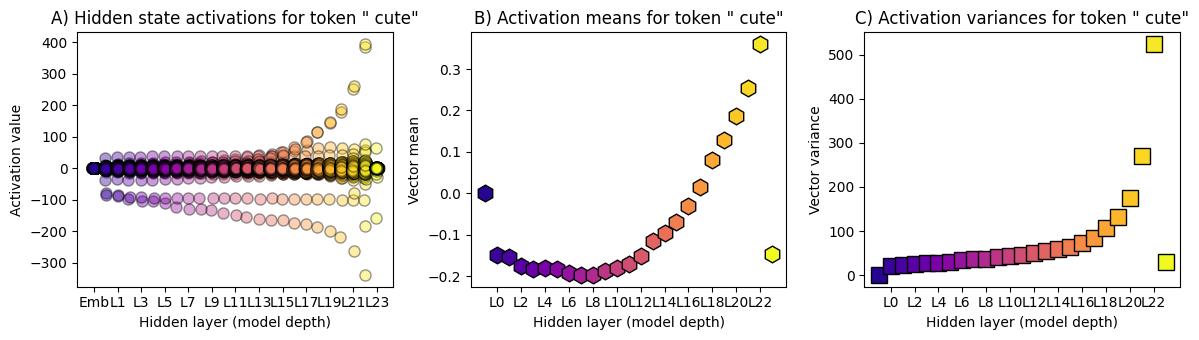

In [38]:
# all hidden-states for one token
whichToken = 8

# initialize stdev matrix
token_stds = torch.zeros((num_hidden,num_tokens))

# setup the figure
_,axs = plt.subplots(1,3,figsize=(12,3.5))

# loop over layers
for layeri in range(num_hidden):

  # extract the activations from this layer and this token
  acts = hs[layeri][0,whichToken,:]

  # plot all the activations
  axs[0].plot(np.random.normal(layeri,.05,hidden_dim),acts,'ko',markersize=8,
           markerfacecolor=plt.cm.plasma((layeri+1)/num_hidden),alpha=.4)

  axs[1].plot(layeri,acts.mean(),'kh',markersize=12,
           markerfacecolor=plt.cm.plasma((layeri+1)/num_hidden))

  # plot the variance of the activations
  axs[2].plot(layeri,acts.var(),'ks',markersize=12,
           markerfacecolor=plt.cm.plasma((layeri+1)/num_hidden))

  # standard deviation for all tokens
  token_stds[layeri,:] = hs[layeri][0,:,:].std(dim=-1)

# names of the layers, for the x-axis tick labels
layer_labels = ['Emb'] + [f'L{i}' for i in range(num_hidden-1)]

# adjust the axes
axs[0].set(xticks=range(0,num_hidden,2),xticklabels=layer_labels[::2],xlabel='Hidden layer (model depth)',
           ylabel='Activation value',title=f'A) Hidden state activations for token "{tokenizer.decode(tokens['input_ids'][0,whichToken])}"')

axs[1].set(xticks=range(1,num_hidden,2),xticklabels=layer_labels[1::2],xlabel='Hidden layer (model depth)',
           ylabel='Vector mean',title=f'B) Activation means for token "{tokenizer.decode(tokens['input_ids'][0,whichToken])}"')

axs[2].set(xticks=range(1,num_hidden,2),xticklabels=layer_labels[1::2],xlabel='Hidden layer (model depth)',
           ylabel='Vector variance',title=f'C) Activation variances for token "{tokenizer.decode(tokens['input_ids'][0,whichToken])}"')


plt.tight_layout()
plt.show()

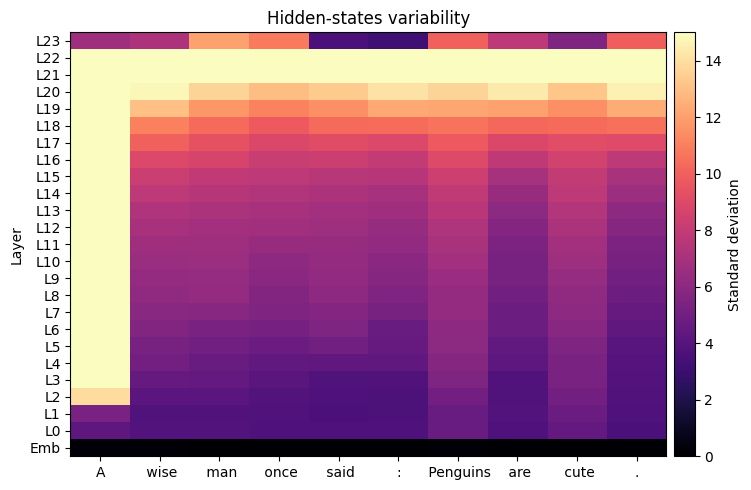

In [39]:
plt.figure(figsize=(8,5))
plt.imshow(token_stds,aspect='auto',origin='lower',
           vmin=0,vmax=15,cmap='magma')
plt.gca().set(ylabel='Layer',xticks=range(num_tokens),title='Hidden-states variability',
              xticklabels=[tokenizer.decode(t) for t in tokens['input_ids'][0]],
              yticks=range(num_hidden),yticklabels=layer_labels)
ch = plt.colorbar(pad=.01)
ch.set_label('Standard deviation')

plt.tight_layout()
plt.show()


# Part 3: Cosine similarities across layers


## Task_1:
- Identify the four token positions that are evenly spaced between the
first and the last. For each token position, extract the hidden-state
vectors across all layers. Calculate all pairwise (that is, each pair of
layers) cosine similarities for each of the four token positions, and
visualize as heatmaps as in Figure 5.4.

In [42]:
len(tokens['input_ids'][0])

10

In [41]:
np.linspace(0,len(tokens['input_ids'][0])-1,4,dtype=int)

array([0, 3, 6, 9])

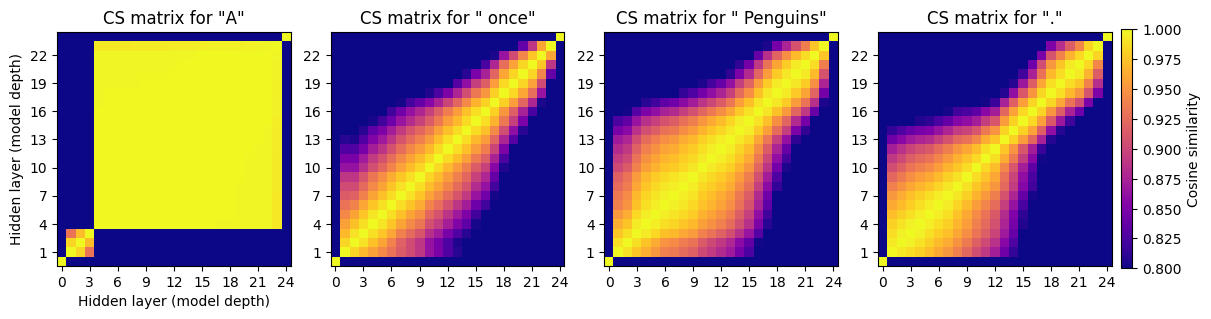

In [43]:

# pick 4 evenly spaced tokens including the first and final
tokens2analyze = np.linspace(0,len(tokens['input_ids'][0])-1,4,dtype=int)

fig,axs = plt.subplots(1,4,layout='constrained',figsize=(12,3))

cos_sims = []

# loop over selected tokens
for toki in range(len(tokens2analyze)):

  # extract the hidden-state activations from this token into a matrix
  all_hiddens = torch.zeros((num_hidden,hidden_dim))
  for layeri in range(num_hidden):
    all_hiddens[layeri,:] = hs[layeri][0,tokens2analyze[toki],:]

  # and calculate the cosine similarity matrix on all pairs of layers
  M = F.cosine_similarity(all_hiddens.unsqueeze(0),all_hiddens.unsqueeze(1),dim=-1)
  cos_sims.append(M)

  # show the matrix
  h = axs[toki].imshow(M,cmap='plasma',vmin=.8,vmax=1,origin='lower')
  axs[toki].set(xticks=range(0,num_hidden,3),yticks=range(1,num_hidden,3),
                title=f'CS matrix for "{tokenizer.decode(tokens["input_ids"][0,tokens2analyze[toki]])}"')

# adjustments
axs[0].set(xlabel='Hidden layer (model depth)',ylabel='Hidden layer (model depth)')
fig.colorbar(h,ax=axs[-1],label='Cosine similarity',pad=.02,shrink=.97)

plt.show()

## Task_2:
- Create a matrix that encodes inter-layer distances. For example,
layers 4 and 7 are three index-units apart. Visualize that matrix as
in Figure 5.5.
Make four scatter plots of distance by similarity as in Figure
5.6. For an additional challenge, use a different color for markers
from each column to visualize the layer the data values come from.

In [44]:
num_hidden,hidden_dim

(25, 1024)

In [48]:
np.arange(num_hidden).shape

(25,)

In [45]:
l=np.arange(num_hidden).reshape(1,-1)

In [47]:
l.shape

(1, 25)

In [49]:
D=abs(l.T-l)

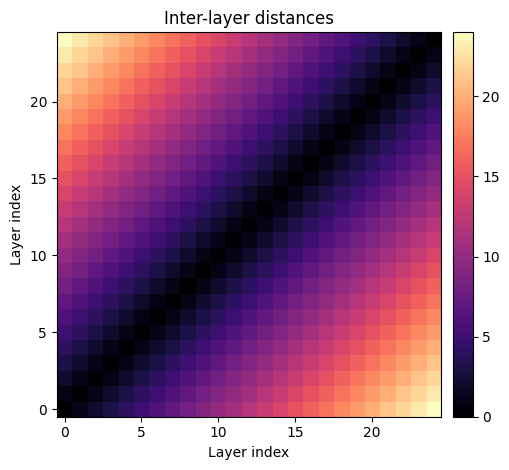

In [56]:
plt.imshow(D,origin='lower',cmap='magma')
plt.colorbar(pad=.02)
plt.gca().set(title='Inter-layer distances',ylabel='Layer index',xlabel='Layer index')

plt.tight_layout()
plt.show()

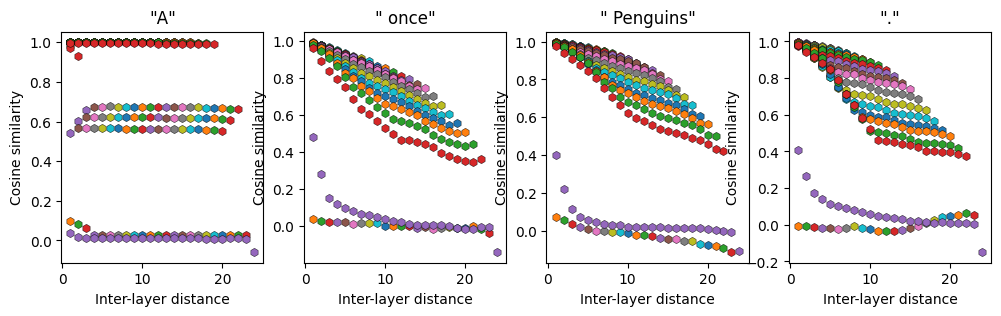

In [57]:

# show the relationships
_,axs = plt.subplots(1,4,figsize=(12,3))

# non-redundant rows and columns
rows,cols = np.nonzero(np.triu(D,1))

for toki in range(len(tokens2analyze)):

  for i in range(num_hidden):
    x = D[rows[cols==i],cols[cols==i]]
    y = cos_sims[toki][rows[cols==i],cols[cols==i]]
    axs[toki].plot(x,y,'h',markeredgecolor='k',markeredgewidth=.3)

  axs[toki].set(xlabel='Inter-layer distance',ylabel='Cosine similarity',
                title=f'"{tokenizer.decode(tokens["input_ids"][0,tokens2analyze[toki]])}"')


plt.show()

# Part 4: Cosine similarities across tokens

## Task_1:
- Identify four linearly spaced layers between the first and the final,
and calculate the cosine similarities across all pairs of hidden-state
vectors within each of those layers. Visualize the results as in Figure
5.7.

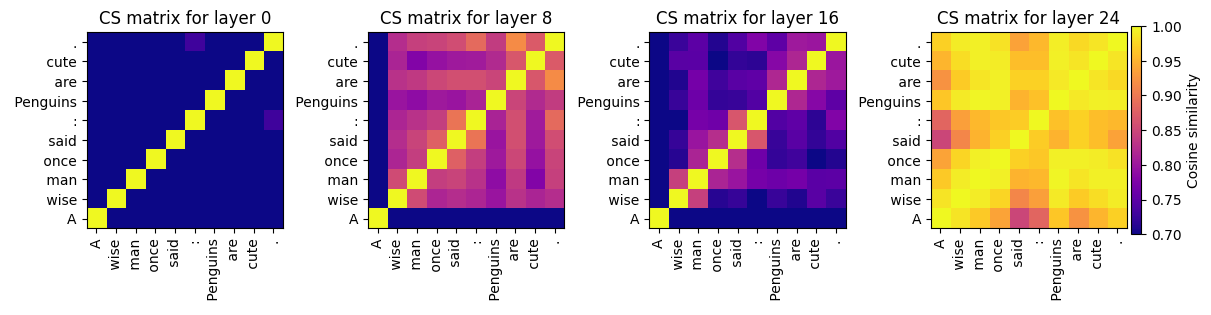

In [58]:
# convert tokens into a list for axis labeling
toks_list = [tokenizer.decode(tokens['input_ids'][0,i]) for i in range(num_tokens)]

# 4 evenly spaced layers
layers2analyze = np.linspace(0,num_hidden-1,4,dtype=int)

fig,axs = plt.subplots(1,4, layout='constrained',figsize=(12,3))

# loop over layers
for layeri in range(len(layers2analyze)):

  # cosine similarity matrix over all token pairs for this layer
  cos_sim = F.cosine_similarity(hs[layers2analyze[layeri]][0,:,:].unsqueeze(0),
                                hs[layers2analyze[layeri]][0,:,:].unsqueeze(1),
                                dim=-1)

  # show the matrix
  h = axs[layeri].imshow(cos_sim,cmap='plasma',vmin=.7,vmax=1,origin='lower')
  axs[layeri].set(xticks=range(num_tokens),yticks=range(num_tokens),yticklabels=toks_list,
                title=f'CS matrix for layer {layers2analyze[layeri]}')
  axs[layeri].set_xticklabels(toks_list,rotation=90)

fig.colorbar(h,ax=axs[-1],label='Cosine similarity',pad=.02,shrink=.96)

plt.show()

## Task_2
- Repeat the inter-token similarity analysis but for all layers. Extract
the non-redundant elements of the cosine similarity matrix, and visu
alize as a scatter plot with similarities on the y-axis and hidden layer
index on the x-axis (Figure 5.8). Exclude the first token from the
analysis

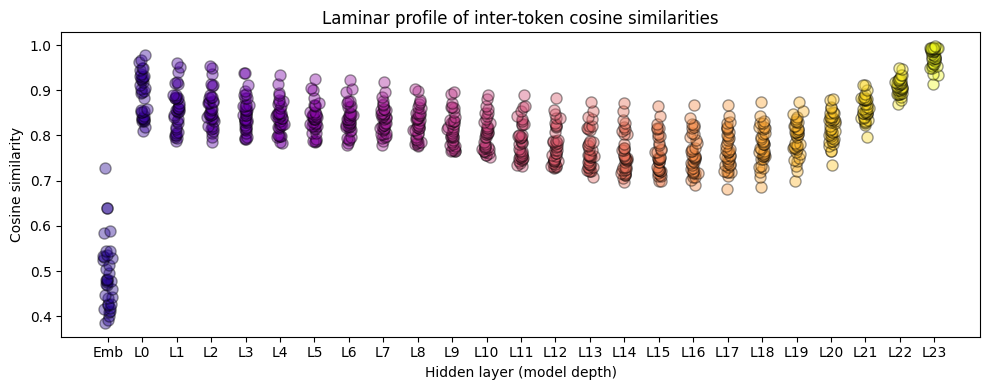

In [59]:

plt.figure(figsize=(10,4))

for layeri in range(num_hidden):

  # similarities across all tokens, excluding the first
  cos_sim = F.cosine_similarity(hs[layeri][0,1:,:].unsqueeze(0),hs[layeri][0,1:,:].unsqueeze(1),dim=-1)
  unique_sim = torch.unique(torch.triu(cos_sim,1))[1:]

  # and plot all the dots
  plt.plot(np.random.normal(layeri,.05,len(unique_sim)),unique_sim,'ko',markersize=8,
           markerfacecolor=plt.cm.plasma((layeri+1)/num_hidden),alpha=.4)

# adjust the axis properties
plt.gca().set(xticks=range(num_hidden),xticklabels=layer_labels,
              xlabel='Hidden layer (model depth)',ylabel='Cosine similarity',
              title=f'Laminar profile of inter-token cosine similarities')

plt.tight_layout()
plt.show()

# Part 5: Descriptives in a larger dataset

## Task_1:
- Import and tokenize the text of The Great Gatsby (see code from
Chapter 2). Extract two non-overlapping segments of 1024 tokens.
Push both sets of tokens through the model.
In a for-loop over hidden-state layers, extract the arithmetic
and L1 means, and standard deviations, of the embeddings vectors
(reminder that the L1 mean is |x|/N whereas the arithmetic mean
is
x/N). Visualize them in separate subplots, and against each
other in a scatter plot, as in Figure 5.9. Exclude the first token in
each sequence from the analysis.
Think about the possible implications of the mean offsets for
inter-token cosine similarity analyses.

In [60]:
model.config.n_ctx

1024

In [61]:

url = 'https://www.gutenberg.org/cache/epub/64317/pg64317.txt'
text = requests.get(url).text
tokens = np.array( tokenizer.encode(text) )
print(f'There are {len(tokens):,} tokens, {len(set(tokens))} of which are unique.')

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (89263 > 1024). Running this sequence through the model will result in indexing errors


There are 89,263 tokens, 8151 of which are unique.


In [62]:
# get some data
batch = torch.zeros((2,model.config.n_ctx),dtype=torch.long)
batch[0,:] = torch.tensor(tokens[10000:10000+model.config.n_ctx])
batch[1,:] = torch.tensor(tokens[20000:20000+model.config.n_ctx])

with torch.no_grad():
  outs = model(batch,output_hidden_states=True)

# check the shape
outs.hidden_states[4].shape


torch.Size([2, 1024, 1024])

In [67]:
outs.logits.shape

torch.Size([2, 1024, 50257])

In [73]:
len(outs.hidden_states)

25

In [95]:
outs.hidden_states[0][1]

tensor([[-0.1361, -0.0412, -0.0960,  ...,  0.0570, -0.0610, -0.0313],
        [ 0.0443, -0.0170, -0.0884,  ..., -0.0020, -0.0007,  0.0322],
        [ 0.0522, -0.1405, -0.0311,  ..., -0.0094,  0.0403, -0.0201],
        ...,
        [-0.0830,  0.0349, -0.1089,  ...,  0.0333, -0.1433,  0.0493],
        [ 0.0216,  0.0243, -0.0527,  ..., -0.0217, -0.1134, -0.0274],
        [-0.1053, -0.0299, -0.0747,  ...,  0.0557, -0.0672, -0.0298]])

In [82]:
outs.hidden_states[0][1][1]

tensor([ 0.0443, -0.0170, -0.0884,  ..., -0.0020, -0.0007,  0.0322])

In [65]:
tokens.shape

(89263,)

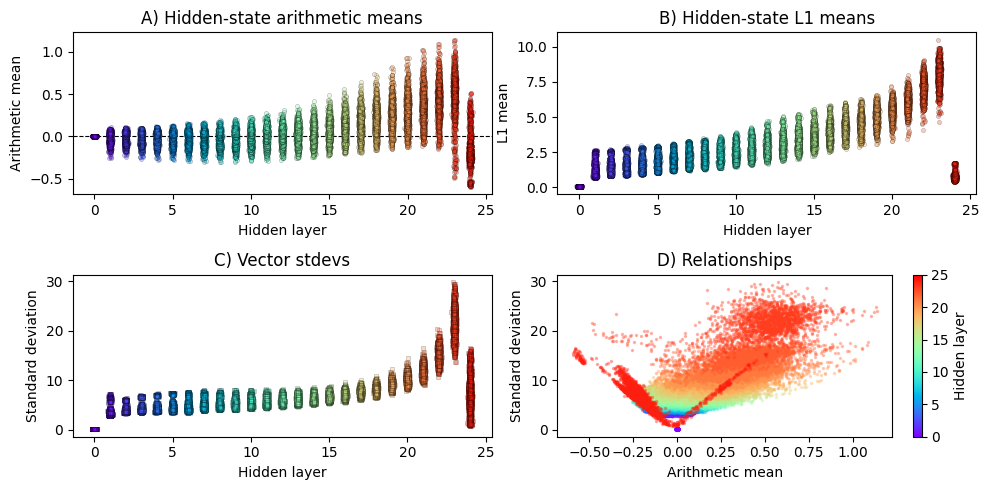

In [96]:
_,axs = plt.subplots(2,2,figsize=(10,5))

# normalization function for mapping layer index onto color
norm = mpl.colors.Normalize(vmin=0,vmax=num_hidden)


for layeri in range(num_hidden):

  # extract means and stdevs of hidden state vectors
  mAbs = abs(outs.hidden_states[layeri][:,1:,:]).mean(dim=-1).flatten()
  m = outs.hidden_states[layeri][:,1:,:].mean(dim=-1).flatten()
  s = outs.hidden_states[layeri][:,1:,:].std(dim=-1).flatten()

  # plot the individual characteristics
  axs[0,0].plot(np.random.normal(layeri,.05,len(m)),m,'ko',markersize=3,alpha=.3,
                markeredgewidth=.4,markerfacecolor=plt.cm.rainbow(layeri/num_hidden))
  axs[0,1].plot(np.random.normal(layeri,.05,len(m)),mAbs,'ko',markersize=3,alpha=.3,
                markeredgewidth=.4,markerfacecolor=plt.cm.rainbow(layeri/num_hidden))

  axs[1,0].plot(np.random.normal(layeri,.05,len(s)),s,'ks',markersize=3,alpha=.3,
              markeredgewidth=.4,markerfacecolor=plt.cm.rainbow(layeri/num_hidden))

  # and their relationships
  axs[1,1].plot(m,s,'.',alpha=.3,markersize=3,color=mpl.cm.rainbow(norm(layeri)))


# final adjustments
axs[0,0].axhline(0,color='k',linestyle='--',linewidth=.8,zorder=-1000)
axs[0,0].set(xlabel='Hidden layer',ylabel='Arithmetic mean',title='A) Hidden-state arithmetic means')
axs[0,1].set(xlabel='Hidden layer',ylabel='L1 mean',title='B) Hidden-state L1 means')
axs[1,0].set(xlabel='Hidden layer',ylabel='Standard deviation',title='C) Vector stdevs')
axs[1,1].set(xlabel='Arithmetic mean',ylabel='Standard deviation',title='D) Relationships')


# add colorbars
sm = mpl.cm.ScalarMappable(cmap=mpl.cm.rainbow,norm=norm)
cbar = plt.colorbar(sm,ax=axs[1,1])
cbar.set_label('Hidden layer')

plt.tight_layout()
plt.show()